# TMDB movie analysis

I fetch 18 movies, clean them, check profit, ratings and distributions, then draw charts.

In [1]:
import pandas as pd
from src.tmdb_client import fetch_all

records = fetch_all()
df_raw = pd.DataFrame(records)
print(len(df_raw))
df_raw[["title", "budget", "revenue"]].head()

loaded backup 18 movies
18


,title,budget,revenue
0,Avengers: Endgame,356000000,2927449455
1,Avatar,237000000,2923706026
2,Star Wars: The Force Awakens,245000000,2068223624
3,Avengers: Infinity War,300000000,2052415039
4,Titanic,200000000,2264162353


## clean

Drop bad columns, join lists with |, fix types, dollars to millions, keep Released.

In [2]:
from src.cleaning import clean

df_cleaned = clean(df_raw)
print(df_cleaned.shape)
df_cleaned[["title", "genres", "budget_musd", "revenue_musd"]].head()

(18, 22)


,title,genres,budget_musd,revenue_musd
0,Avengers: Endgame,Adventure|Science Fiction|Action,356.0,2927.449455
1,Avatar,Science Fiction|Action|Adventure,237.0,2923.706026
2,Star Wars: The Force Awakens,Adventure|Action|Science Fiction,245.0,2068.223624
3,Avengers: Infinity War,Adventure|Action|Science Fiction,300.0,2052.415039
4,Titanic,Drama|Romance,200.0,2264.162353


## eda - distributions and outliers

before reading kpi numbers, look at the spread of the numeric columns
they rest on. histograms for shape, boxplots for outliers.


In [3]:
import matplotlib.pyplot as plt

df_cleaned[["budget_musd", "revenue_musd", "runtime", "vote_average",
            "popularity", "vote_count"]].describe().round(2)


,budget_musd,revenue_musd,runtime,vote_average,popularity,vote_count
count,18.00,18.00,18.00,18.00,18.00,18.00
mean,213.78,1699.04,138.00,7.39,41.95,21701.33
std,61.96,537.61,23.85,0.53,22.21,8725.42
min,125.00,1243.23,102.00,6.50,18.11,10507.00
25%,162.50,1336.18,125.25,7.12,28.00,14559.50
50%,200.00,1484.54,135.50,7.25,33.61,21498.50
75%,243.00,1957.20,147.50,7.83,44.56,27196.25
max,356.00,2927.45,194.00,8.24,96.86,40006.00


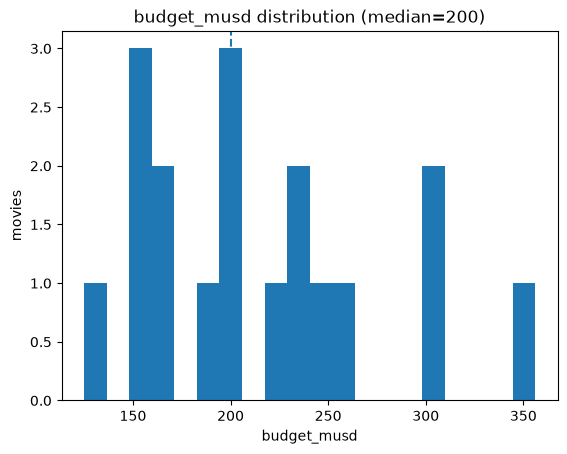

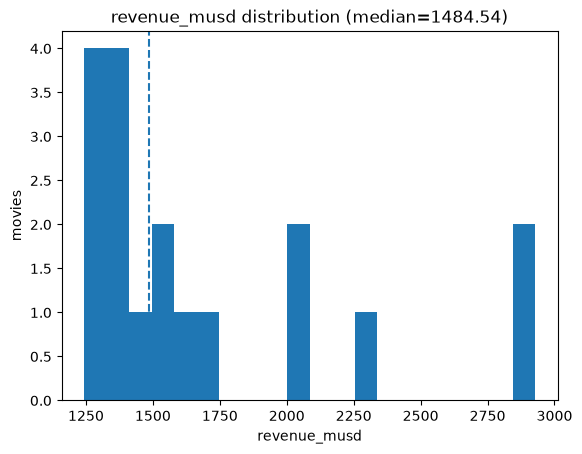

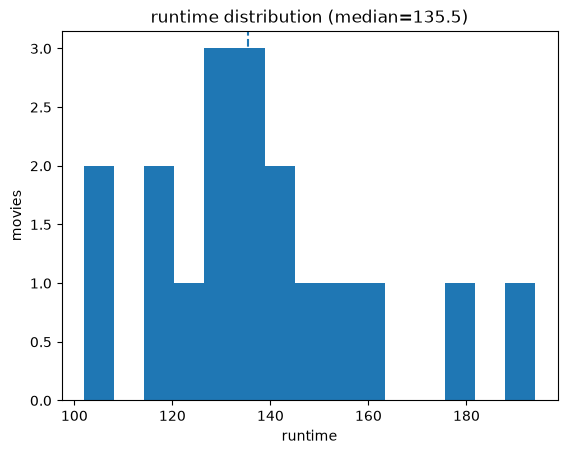

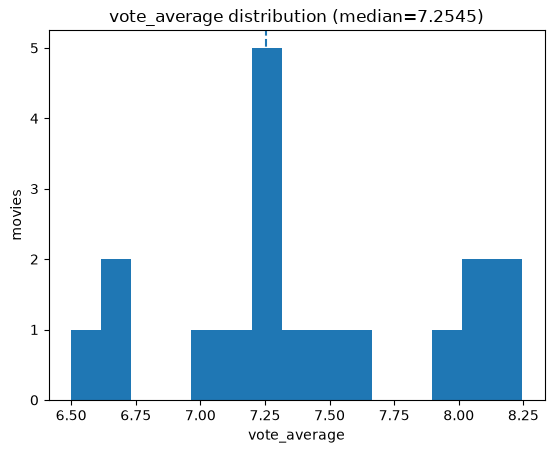

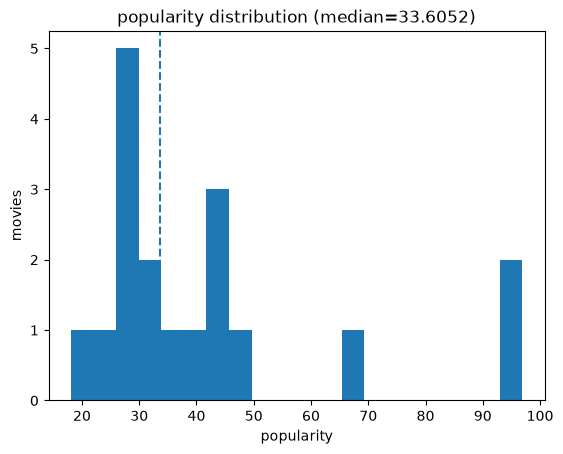

In [4]:
from src.visualize import plot_distribution

plot_distribution(df_cleaned, "budget_musd")
plt.show()

plot_distribution(df_cleaned, "revenue_musd")
plt.show()

plot_distribution(df_cleaned, "runtime", bins=15)
plt.show()

plot_distribution(df_cleaned, "vote_average", bins=15)
plt.show()

plot_distribution(df_cleaned, "popularity")
plt.show()


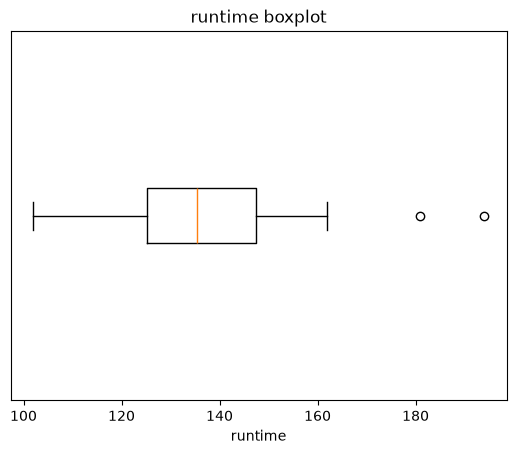

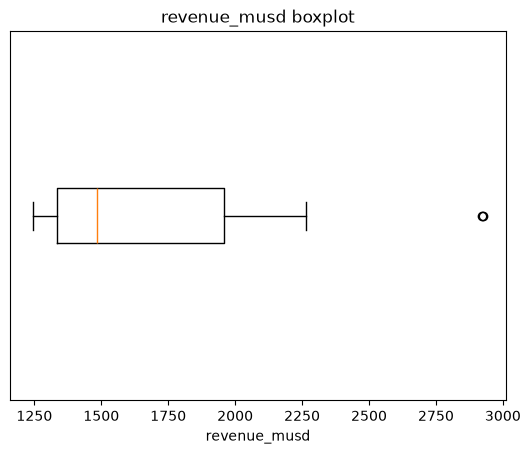

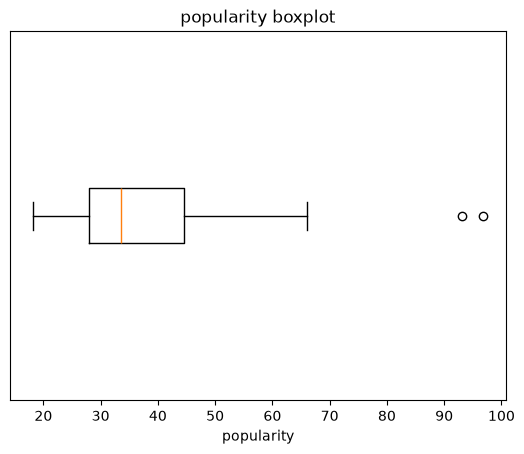

In [5]:
from src.visualize import plot_boxplot

plot_boxplot(df_cleaned, "runtime")
plt.show()

plot_boxplot(df_cleaned, "revenue_musd")
plt.show()

plot_boxplot(df_cleaned, "popularity")
plt.show()


what the distributions say on this 18-movie set:

- budgets are tight: 125-356 musd, median 200, and mean 214 sits a bit
  above the median, so the sample leans expensive but has no extreme.
- revenue is right-skewed: median 1,485 vs mean 1,699, and the max is
  ~6.2x the min. past the upper fence (2,889): endgame and avatar.
- runtime clusters at 102-194 min, median 135.5. only titanic (194) and
  endgame (181) blow the 181 fence - long runtimes are the exception.
- ratings barely move: 6.5-8.24, zero outliers. expected, this list is
  the heavily-voted blockbusters, not a random sample of all films.
- popularity is the most skewed: median 33.6 but max 96.9, driven by the
  two avengers films (96.9, 93.1). that is release-window buzz, not a
  stable signal, so i treat popularity differently from ratings.

none of the flagged points are errors - they are the real biggest films.
review-wise: for revenue and popularity, medians describe this data more
honestly than means, which is why franchise roi is reported as a median.


## check the extracted columns

The brief asks for value_counts on the columns I built, to spot odd values before I trust them.

In [6]:
from src.cleaning import inspect_anomalies

EXTRACTED = ["belongs_to_collection", "genres", "spoken_languages",
              "production_countries", "production_companies", "original_language"]
counts = inspect_anomalies(df_cleaned, EXTRACTED)

belongs_to_collection
belongs_to_collection
The Avengers Collection                4
Star Wars Collection                   2
NaN                                    2
Jurassic Park Collection               2
Frozen Collection                      2
Avatar Collection                      1
The Lion King (Reboot) Collection      1
The Fast and the Furious Collection    1
Black Panther Collection               1
Harry Potter Collection                1
Name: count, dtype: int64
genres
genres
Adventure|Action|Science Fiction             3
Science Fiction|Action|Adventure             2
Adventure|Science Fiction|Thriller           2
Action|Adventure|Science Fiction             2
Adventure|Science Fiction|Action             1
Drama|Romance                                1
Adventure|Drama|Family|Animation             1
Action|Crime|Thriller                        1
Adventure|Fantasy                            1
Family|Animation|Adventure|Comedy|Fantasy    1
Name: count, dtype: int64
spoken_lan

## profit and roi

In [7]:
from src.kpis import add_profit_roi, rank

df_enriched = add_profit_roi(df_cleaned)
print(df_enriched[["title", "profit", "roi"]].head())

print("top revenue")
print(rank(df_enriched, "revenue_musd")["title"].tolist())
print("top profit")
print(rank(df_enriched, "profit")["title"].tolist())
print("low profit")
print(rank(df_enriched, "profit", ascending=True)["title"].tolist())

                          title       profit        roi
0             Avengers: Endgame  2571.449455   8.223173
1                        Avatar  2686.706026  12.336312
2  Star Wars: The Force Awakens  1823.223624   8.441729
3        Avengers: Infinity War  1752.415039   6.841383
4                       Titanic  2064.162353  11.320812
top revenue
['Avengers: Endgame', 'Avatar', 'Titanic', 'Star Wars: The Force Awakens', 'Avengers: Infinity War']
top profit
['Avatar', 'Avengers: Endgame', 'Titanic', 'Star Wars: The Force Awakens', 'Avengers: Infinity War']
low profit
['Star Wars: The Last Jedi', 'Incredibles 2', 'Beauty and the Beast', 'Frozen', 'Jurassic World: Fallen Kingdom']


## more rankings

In [8]:
print("top budget")
print(rank(df_enriched, "budget_musd")["title"].tolist())
print("most voted")
print(rank(df_enriched, "vote_count")["title"].tolist())
print("most popular")
print(rank(df_enriched, "popularity")["title"].tolist())

rich = df_enriched[df_enriched["budget_musd"] >= 10]
print("top roi")
print(rank(rich, "roi")["title"].tolist())
print("low roi")
print(rank(rich, "roi", ascending=True)["title"].tolist())

voted = df_enriched[df_enriched["vote_count"] >= 10]
print("top rated")
print(rank(voted, "vote_average")["title"].tolist())
print("low rated")
print(rank(voted, "vote_average", ascending=True)["title"].tolist())

top budget
['Avengers: Endgame', 'Avengers: Infinity War', 'Star Wars: The Last Jedi', 'The Lion King', 'Star Wars: The Force Awakens']
most voted
['The Avengers', 'Avatar', 'Avengers: Infinity War', 'Avengers: Endgame', 'Titanic']
most popular
['Avengers: Endgame', 'Avengers: Infinity War', 'The Avengers', 'Avengers: Age of Ultron', 'Beauty and the Beast']
top roi
['Avatar', 'Titanic', 'Jurassic World', 'Harry Potter and the Deathly Hallows: Part 2', 'Frozen II']
low roi
['Star Wars: The Last Jedi', 'Avengers: Age of Ultron', 'Incredibles 2', 'The Lion King', 'Black Panther']
top rated
['Avengers: Infinity War', 'Avengers: Endgame', 'Harry Potter and the Deathly Hallows: Part 2', 'The Avengers', 'Titanic']
low rated
['Jurassic World: Fallen Kingdom', 'Star Wars: The Last Jedi', 'Jurassic World', 'Beauty and the Beast', 'The Lion King']


## searches

In [9]:
from src.kpis import search_willis_scifi_action, search_thurman_tarantino

w = search_willis_scifi_action(df_enriched)
print("willis found:", len(w))
print(w[["title", "vote_average"]] if len(w) > 0 else "no match in this set")

t = search_thurman_tarantino(df_enriched)
print("thurman found:", len(t))
print(t[["title", "runtime"]] if len(t) > 0 else "no match in this set")

willis found: 0
no match in this set
thurman found: 0
no match in this set


## franchise and directors

In [10]:
from src.kpis import franchise_vs_standalone, top_franchises, top_directors

print(franchise_vs_standalone(df_enriched))
print(top_franchises(df_enriched).head())
print(top_directors(df_enriched).head())

            movies  mean_revenue  median_roi  mean_budget  mean_popularity  \
group                                                                        
franchise       16   1690.775863    7.842215        218.0        41.897306   
standalone       2   1765.139159    9.617018        180.0        42.342550   

            mean_rating  
group                    
franchise       7.38375  
standalone      7.45050  
                  franchise  movies  total_revenue  mean_revenue  \
0   The Avengers Collection       4    7904.083703   1976.020926   
1      Star Wars Collection       2    3402.631330   1701.315665   
2  Jurassic Park Collection       2    2982.006481   1491.003241   
3         Avatar Collection       1    2923.706026   2923.706026   
4         Frozen Collection       2    2727.902485   1363.951242   

   total_budget  mean_budget  mean_rating  
0        1111.0       277.75      7.95625  
1         545.0       272.50      6.95000  
2         320.0       160.00      6.60150 

## charts

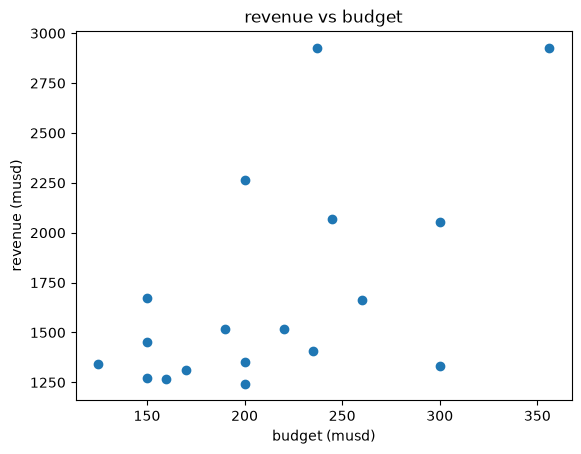

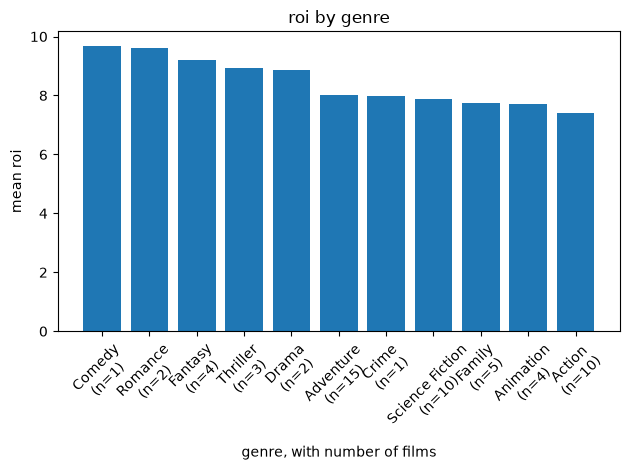

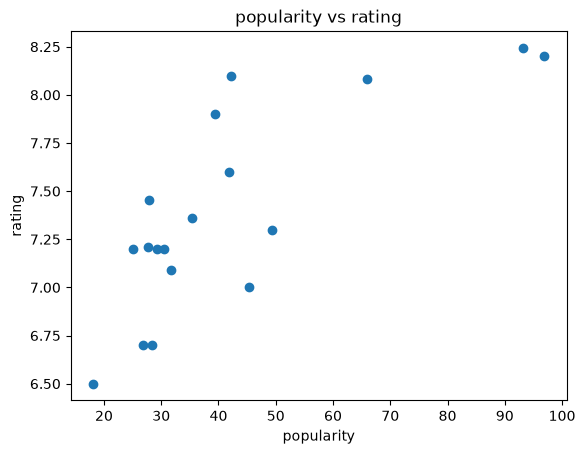

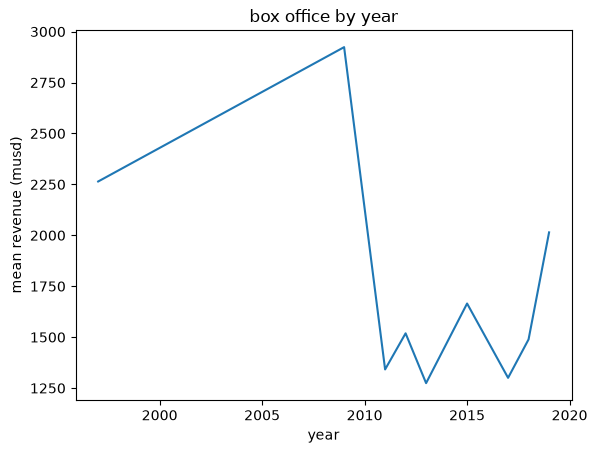

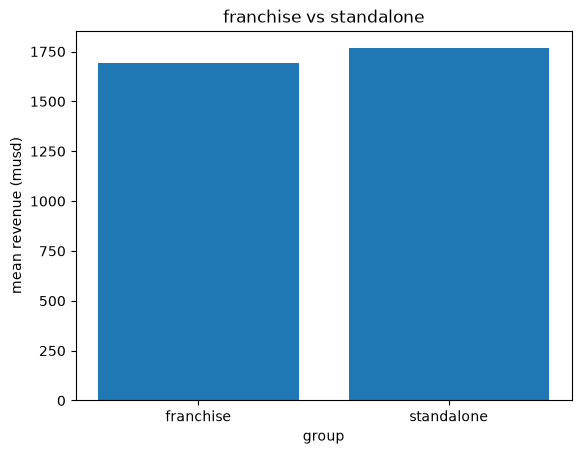

In [11]:
import matplotlib.pyplot as plt
from src.visualize import plot_revenue_vs_budget, plot_roi_by_genre, plot_popularity_vs_rating, plot_yearly_box_office, plot_franchise_vs_standalone

plot_revenue_vs_budget(df_enriched)
plt.show()

plot_roi_by_genre(df_enriched)
plt.tight_layout()
plt.show()

plot_popularity_vs_rating(df_enriched)
plt.show()

plot_yearly_box_office(df_enriched)
plt.show()

plot_franchise_vs_standalone(df_enriched)
plt.show()